# 06. Convolutional Neural Networks (CNNs)
## From convolution mathematics to image classification with PyTorch

This notebook covers the core mathematics, implementation details, training workflow, evaluation, and debugging of CNNs.

### Learning objectives
- Explain local connectivity, shared filters, channels, feature maps, stride, padding, and pooling.
- Calculate convolution output shapes and parameter counts.
- Build CNNs with `torch.nn.Conv2d`.
- Train and evaluate a CNN using a reliable PyTorch workflow.
- Interpret loss curves, confusion matrices, and class-wise metrics.
- Visualize learned filters and intermediate feature maps.
- Understand normalization, augmentation, batch normalization, dropout, and checkpointing.
- Recognize common CNN errors and prevent data leakage.

**Prerequisites:** Python, NumPy, Matplotlib, basic neural networks, and PyTorch fundamentals.

The primary dataset is Fashion-MNIST through `torchvision`. The notebook includes a synthetic-image fallback if `torchvision` or downloading the dataset is unavailable. The fallback teaches the mechanics of CNNs but is not a substitute for a real benchmark.

## 1. Why use a CNN?

For an image of height \(H\), width \(W\), and \(C\) channels, a fully connected network may flatten the image into \(HWC\) features. This can create many parameters and discards the explicit spatial structure.

CNNs use:

- **Local connectivity:** each filter examines a small neighborhood.
- **Parameter sharing:** the same filter is applied at many image locations.
- **Hierarchical features:** layers can combine simple patterns into more complex ones.

PyTorch expects image batches in **NCHW** order:

$$
(N, C, H, W)
$$

Here, \(N\) is batch size, \(C\) is channel count, \(H\) is height, and \(W\) is width. Grayscale images usually have \(C=1\); RGB images have \(C=3\).

In [1]:
import copy
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)

# Example batch: 8 grayscale images of size 28 x 28.
example_images = torch.randn(8, 1, 28, 28)
print("Batch shape:", example_images.shape)
print("One image shape:", example_images[0].shape)

PyTorch: 2.5.1+cu121
Device: cuda
Batch shape: torch.Size([8, 1, 28, 28])
One image shape: torch.Size([1, 28, 28])


## 2. What does a convolution do?

A filter (kernel) slides across an image and computes weighted sums of local neighborhoods. Deep-learning libraries commonly call this convolution, although the operation is technically cross-correlation.

For a single-channel input \(X\) and kernel \(K\), a simplified valid operation is:

$$
Y(i,j) = \sum_{u=0}^{k_H-1}\sum_{v=0}^{k_W-1}
K(u,v)X(i+u,j+v)
$$

A real layer combines multiple input channels, multiple learned filters, and usually a bias. Each output channel becomes a **feature map**.

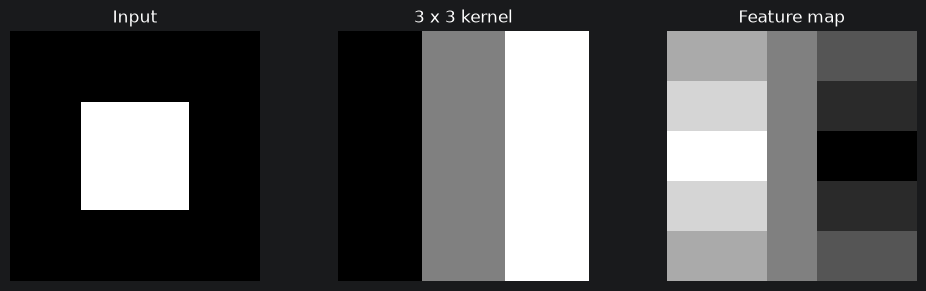

In [2]:
# Apply a hand-designed vertical-edge filter to a toy image.
toy_image = torch.zeros(1, 1, 7, 7)
toy_image[0, 0, 2:5, 2:5] = 1.0
edge_kernel = torch.tensor([
    [-1., 0., 1.],
    [-1., 0., 1.],
    [-1., 0., 1.]
]).reshape(1, 1, 3, 3)

toy_features = nn.functional.conv2d(toy_image, edge_kernel)
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(toy_image[0, 0], cmap="gray")
axes[0].set_title("Input")
axes[1].imshow(edge_kernel[0, 0], cmap="gray")
axes[1].set_title("3 x 3 kernel")
axes[2].imshow(toy_features[0, 0], cmap="gray")
axes[2].set_title("Feature map")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Kernel size, stride, padding, and output dimensions

- **Kernel size:** spatial size of the filter, such as \(3\times3\).
- **Stride:** number of pixels moved at each step.
- **Padding:** extra border pixels, often zeros, added around the input.
- **Dilation:** spacing between kernel elements.

For one spatial dimension, the output size is:

$$
H_{\text{out}} =
\left\lfloor
\frac{H_{\text{in}} + 2P - D(K-1) - 1}{S} + 1
\right\rfloor
$$

Here \(P\) is padding, \(D\) is dilation, \(K\) is kernel size, and \(S\) is stride. The same formula applies to width.

For a \(3\times3\) kernel, stride 1, and padding 1, height and width are preserved when dilation is 1.

In [3]:
def conv_output_size(input_size, kernel_size, stride=1, padding=0, dilation=1):
    # Calculate one spatial dimension of a convolution output.
    return ((input_size + 2 * padding - dilation * (kernel_size - 1) - 1)
            // stride + 1)

for params in [
    {"kernel_size": 3, "stride": 1, "padding": 0},
    {"kernel_size": 3, "stride": 1, "padding": 1},
    {"kernel_size": 3, "stride": 2, "padding": 1},
    {"kernel_size": 5, "stride": 2, "padding": 2},
]:
    print(params, "->", conv_output_size(28, **params))

{'kernel_size': 3, 'stride': 1, 'padding': 0} -> 26
{'kernel_size': 3, 'stride': 1, 'padding': 1} -> 28
{'kernel_size': 3, 'stride': 2, 'padding': 1} -> 14
{'kernel_size': 5, 'stride': 2, 'padding': 2} -> 14


## 4. Channels, filters, and parameter count

Each output filter spans **all input channels**. With \(C_{\text{in}}\) input channels, \(C_{\text{out}}\) output channels, and kernel size \(K_H\times K_W\), the number of trainable parameters is:

$$
\text{parameters} =
C_{\text{out}} C_{\text{in}} K_H K_W + C_{\text{out}}
$$

The final term counts biases when `bias=True`.

For example, `Conv2d(3, 16, kernel_size=3)` learns 16 filters, each spanning all three RGB channels.

In [4]:
conv = nn.Conv2d(3, 16, kernel_size=3)
print("Weight shape:", tuple(conv.weight.shape))
print("Bias shape:", tuple(conv.bias.shape))
print("Parameter count:", sum(p.numel() for p in conv.parameters()))

rgb_batch = torch.randn(4, 3, 32, 32)
print("Output shape:", tuple(conv(rgb_batch).shape))

Weight shape: (16, 3, 3, 3)
Bias shape: (16,)
Parameter count: 448
Output shape: (4, 16, 30, 30)


## 5. Activations and pooling

A common activation is ReLU:

$$
\operatorname{ReLU}(x) = \max(0,x)
$$

Nonlinear activations allow stacked layers to learn nonlinear functions. Pooling reduces spatial resolution:

- **Max pooling:** takes the maximum value in each local window.
- **Average pooling:** takes the average value in each local window.

Pooling is not mandatory in every modern CNN. Strided convolutions and global average pooling are common alternatives.

In [5]:
# Compare max pooling and average pooling on a tiny feature map.
feature_map = torch.tensor([
    [1., 2., 3., 4.],
    [5., 6., 7., 8.],
    [9., 1., 2., 3.],
    [4., 5., 6., 7.]
]).reshape(1, 1, 4, 4)

print("Original:\n", feature_map[0, 0])
print("Max pooled:\n", nn.functional.max_pool2d(feature_map, 2, 2)[0, 0])
print("Average pooled:\n", nn.functional.avg_pool2d(feature_map, 2, 2)[0, 0])

Original:
 tensor([[1., 2., 3., 4.],
        [5., 6., 7., 8.],
        [9., 1., 2., 3.],
        [4., 5., 6., 7.]])
Max pooled:
 tensor([[6., 8.],
        [9., 7.]])
Average pooled:
 tensor([[3.5000, 5.5000],
        [4.7500, 4.5000]])


## 6. Follow the tensor shapes through a CNN

Consider a grayscale \(28\times28\) input:

- `Conv2d(1, 16, 3, padding=1)` produces \(16\times28\times28\).
- `MaxPool2d(2)` produces \(16\times14\times14\).
- `Conv2d(16, 32, 3, padding=1)` produces \(32\times14\times14\).
- `MaxPool2d(2)` produces \(32\times7\times7\).

Flattening gives \(32\cdot7\cdot7=1568\) features per image.

In [6]:
class ShapeDemoCNN(nn.Module):
    # A feature extractor used to verify layer output dimensions.
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

    def forward(self, x):
        return self.features(x)

shape_model = ShapeDemoCNN()
shape_output = shape_model(torch.randn(4, 1, 28, 28))
print("Feature tensor:", tuple(shape_output.shape))
print("Flattened features per image:", shape_output[0].numel())

Feature tensor: (4, 32, 7, 7)
Flattened features per image: 1568


## 7. Load Fashion-MNIST, with a fallback

Fashion-MNIST contains 28×28 grayscale clothing images in 10 classes. Its first download requires a working connection. If importing `torchvision` or downloading data fails, the fallback below creates ten synthetic visual-pattern classes so the CNN workflow can still run.

The fallback is educational only; do not compare its results directly with Fashion-MNIST benchmark results.

In [7]:
USE_SYNTHETIC_FALLBACK = False
dataset_source = None

try:
    from torchvision import datasets, transforms

    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])
    train_full = datasets.FashionMNIST(
        root="./data", train=True, download=True, transform=transform
    )
    test_dataset = datasets.FashionMNIST(
        root="./data", train=False, download=True, transform=transform
    )
    class_names = [
        "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
        "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
    ]
    dataset_source = "Fashion-MNIST"
except Exception as exc:
    print("Fashion-MNIST unavailable:", repr(exc))
    USE_SYNTHETIC_FALLBACK = True

if USE_SYNTHETIC_FALLBACK:
    # Create ten classes of simple patterns with small random variations.
    def make_synthetic_images(n_per_class=300, image_size=28, seed=42):
        rng = np.random.default_rng(seed)
        images, labels = [], []
        yy, xx = np.indices((image_size, image_size))
        for label in range(10):
            for _ in range(n_per_class):
                img = np.zeros((image_size, image_size), dtype=np.float32)
                shift = int(rng.integers(-2, 3))
                thickness = int(rng.integers(2, 5))
                if label == 0:  # Horizontal bars
                    for row in (6, 13, 20):
                        r = row + shift
                        img[max(0, r):min(image_size, r+thickness), :] = 1
                elif label == 1:  # Vertical bars
                    for col in (6, 13, 20):
                        c = col + shift
                        img[:, max(0, c):min(image_size, c+thickness)] = 1
                elif label == 2:  # Main diagonal
                    img[np.abs(yy - xx - shift) <= thickness] = 1
                elif label == 3:  # Anti-diagonal
                    img[np.abs(yy + xx - (image_size-1) - shift) <= thickness] = 1
                elif label == 4:  # Outer frame
                    img[:thickness, :] = 1
                    img[-thickness:, :] = 1
                    img[:, :thickness] = 1
                    img[:, -thickness:] = 1
                elif label == 5:  # Center square
                    start = 7 + shift
                    img[max(0,start):min(image_size,start+14),
                        max(0,start):min(image_size,start+14)] = 1
                elif label == 6:  # Disk
                    img[(xx-14-shift)**2 + (yy-14)**2 < 7**2] = 1
                elif label == 7:  # Cross
                    img[12:16, :] = 1
                    img[:, 12:16] = 1
                elif label == 8:  # Two blocks
                    img[4:10, 4:10] = 1
                    img[18:24, 18:24] = 1
                else:  # Checkerboard
                    tile = int(rng.integers(3, 6))
                    img[((yy // tile + xx // tile) % 2) == 0] = 1
                img += rng.normal(0, 0.12, img.shape).astype(np.float32)
                img = np.clip(img, 0, 1)
                images.append(img[None, :, :])
                labels.append(label)

        return torch.tensor(np.stack(images)), torch.tensor(labels, dtype=torch.long)

    all_images, all_labels = make_synthetic_images()
    permutation = torch.randperm(len(all_labels))
    all_images, all_labels = all_images[permutation], all_labels[permutation]
    n_total = len(all_labels)
    n_train, n_val = int(0.70*n_total), int(0.15*n_total)
    train_dataset = TensorDataset(all_images[:n_train]*2-1, all_labels[:n_train])
    val_dataset = TensorDataset(
        all_images[n_train:n_train+n_val]*2-1,
        all_labels[n_train:n_train+n_val]
    )
    test_dataset = TensorDataset(
        all_images[n_train+n_val:]*2-1,
        all_labels[n_train+n_val:]
    )
    dataset_source = "Synthetic patterns"
else:
    n_train = int(0.9 * len(train_full))
    n_val = len(train_full) - n_train
    split_generator = torch.Generator().manual_seed(SEED)
    train_dataset, val_dataset = random_split(
        train_full, [n_train, n_val], generator=split_generator
    )

print("Dataset:", dataset_source)
print("Train:", len(train_dataset), "| validation:", len(val_dataset),
      "| test:", len(test_dataset))

Failed to download (trying next):
<urlopen error [Errno 11001] getaddrinfo failed>

Fashion-MNIST unavailable: RuntimeError('Error downloading train-images-idx3-ubyte.gz')
Dataset: Synthetic patterns
Train: 2100 | validation: 450 | test: 450


## 8. Inspect images and labels

Inspect examples and class counts before training. This can expose unexpected transformations, incorrect labels, or class imbalance. The visualization maps normalized pixels back into a displayable range when needed.

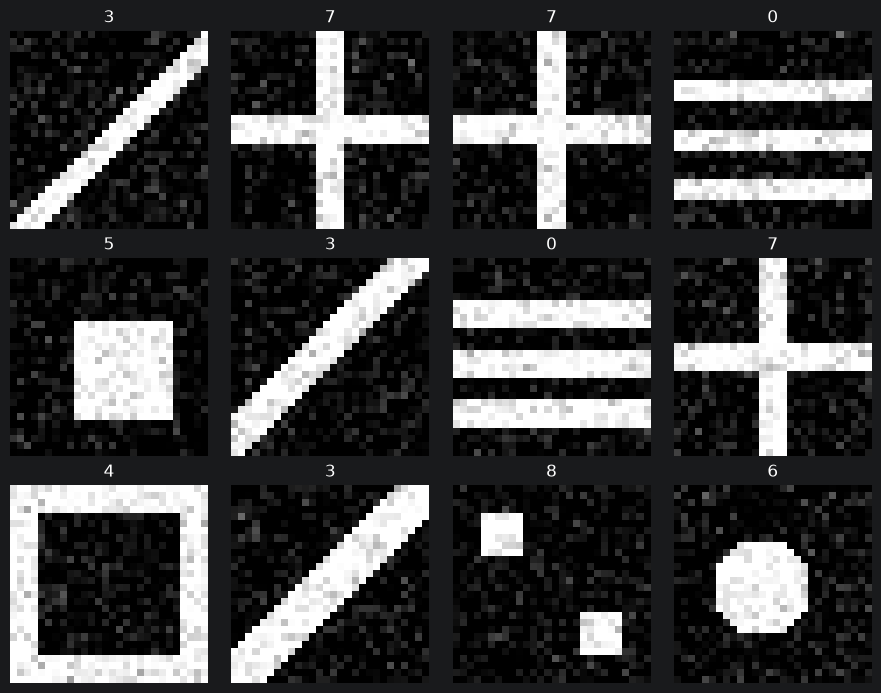

Train class counts: [214 212 208 202 212 210 204 209 215 214]
Validation class counts: [52 35 54 48 43 46 49 46 41 36]
Test class counts: [34 53 38 50 45 44 47 45 44 50]


In [8]:
def show_image_grid(dataset, class_names=None, n_images=12):
    # Display example images with their class labels.
    n_images = min(n_images, len(dataset))
    fig, axes = plt.subplots(3, 4, figsize=(9, 7))
    for i, ax in enumerate(axes.flat):
        if i >= n_images:
            ax.axis("off")
            continue
        image, label = dataset[i]
        image = image.detach().cpu()
        if image.min() < 0:
            image = image * 0.5 + 0.5
        name = class_names[int(label)] if class_names is not None else str(int(label))
        ax.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(name)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_image_grid(train_dataset, class_names if dataset_source == "Fashion-MNIST" else None)

def label_counts(dataset, n_classes=10):
    # Count labels in a dataset, including classes with zero observations.
    labels = [int(label) for _, label in dataset]
    return np.bincount(labels, minlength=n_classes)

print("Train class counts:", label_counts(train_dataset))
print("Validation class counts:", label_counts(val_dataset))
print("Test class counts:", label_counts(test_dataset))

## 9. Build a CNN classifier

The CNN below contains two convolutional blocks and a dense classifier. It returns **logits**, not softmax probabilities, because `nn.CrossEntropyLoss` expects logits and integer class labels.

For \(K\) classes, logits have shape `(batch_size, K)`. The largest logit determines the predicted class.

In [9]:
class SmallCNN(nn.Module):
    # Compact CNN for 28 x 28 grayscale images.
    def __init__(self, num_classes=10, dropout=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 28 -> 14
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)   # 14 -> 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = SmallCNN().to(device)
sample_batch = torch.randn(8, 1, 28, 28, device=device)
sample_logits = model(sample_batch)
print("Input shape:", tuple(sample_batch.shape))
print("Logits shape:", tuple(sample_logits.shape))
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Input shape: (8, 1, 28, 28)
Logits shape: (8, 10)
Trainable parameters: 207018


## 10. DataLoaders and the training loop

Training steps use `model.train()`, cleared gradients, a forward pass, loss calculation, `loss.backward()`, and `optimizer.step()`.

During evaluation, use `model.eval()` and `torch.no_grad()`. These serve different purposes: evaluation mode changes modules such as dropout and batch normalization, while `no_grad()` disables gradient tracking.

In [10]:
BATCH_SIZE = 128
NUM_WORKERS = 0  # Reliable default for notebook and cross-platform use.

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
)
val_loader = DataLoader(
    val_dataset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS
)
test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS
)

def run_epoch(model, loader, criterion, optimizer=None, device=device):
    # If an optimizer is passed, train; otherwise evaluate without updates.
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, total_correct, total_examples = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            n = labels.size(0)
            total_loss += loss.item() * n
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_examples += n

    return total_loss / total_examples, total_correct / total_examples


def fit_model(model, train_loader, val_loader, epochs=8, lr=1e-3,
              weight_decay=1e-4, scheduler=None, patience=None, device=device):
    # Train, track metrics, and restore the best validation-loss weights.
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {key: [] for key in [
        "train_loss", "val_loss", "train_acc", "val_acc", "lr"
    ]}
    best_state = copy.deepcopy(model.state_dict())
    best_val_loss, best_epoch, stale_epochs = float("inf"), 0, 0

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(
            model, train_loader, criterion, optimizer=optimizer, device=device
        )
        val_loss, val_acc = run_epoch(
            model, val_loader, criterion, optimizer=None, device=device
        )
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1

        if scheduler is not None:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        print(f"Epoch {epoch+1:02d}/{epochs} | "
              f"train loss={train_loss:.4f}, acc={train_acc:.3f} | "
              f"val loss={val_loss:.4f}, acc={val_acc:.3f} | "
              f"lr={optimizer.param_groups[0]['lr']:.2e}")

        if patience is not None and stale_epochs >= patience:
            print(f"Early stopping. Best epoch: {best_epoch}")
            break

    model.load_state_dict(best_state)
    return model, history, best_epoch, best_val_loss


def plot_history(history, title="CNN training history"):
    # Plot loss and accuracy to help diagnose learning and overfitting.
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set(title="Cross-entropy loss", xlabel="Epoch", ylabel="Loss")
    axes[0].legend()
    axes[1].plot(epochs, history["train_acc"], label="Train")
    axes[1].plot(epochs, history["val_acc"], label="Validation")
    axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.02))
    axes[1].legend()
    for ax in axes:
        ax.grid(True, alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 11. Train the model

We use `CrossEntropyLoss`, AdamW, and a modest number of epochs so the experiment is practical on a CPU. Increase `EPOCHS` for a more thorough run. Runtime depends on hardware and whether Fashion-MNIST has to be downloaded.

Epoch 01/8 | train loss=0.5593, acc=0.866 | val loss=0.1145, acc=1.000 | lr=1.00e-03
Epoch 02/8 | train loss=0.0105, acc=0.999 | val loss=0.0022, acc=1.000 | lr=1.00e-03
Epoch 03/8 | train loss=0.0029, acc=1.000 | val loss=0.0004, acc=1.000 | lr=1.00e-03
Epoch 04/8 | train loss=0.0009, acc=1.000 | val loss=0.0002, acc=1.000 | lr=1.00e-03
Epoch 05/8 | train loss=0.0006, acc=1.000 | val loss=0.0001, acc=1.000 | lr=1.00e-03
Epoch 06/8 | train loss=0.0007, acc=1.000 | val loss=0.0001, acc=1.000 | lr=1.00e-03
Epoch 07/8 | train loss=0.0005, acc=1.000 | val loss=0.0001, acc=1.000 | lr=1.00e-03
Epoch 08/8 | train loss=0.0007, acc=1.000 | val loss=0.0001, acc=1.000 | lr=1.00e-03
Training time: 1.0 seconds
Best epoch: 7
Best validation loss: 0.0001


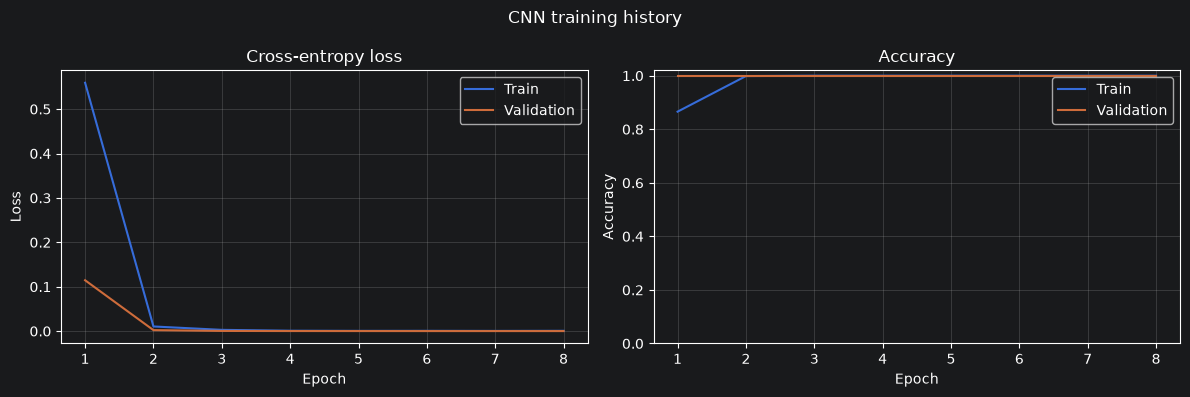

In [11]:
EPOCHS = 8
torch.manual_seed(SEED)
model = SmallCNN().to(device)

start_time = time.time()
model, history, best_epoch, best_val_loss = fit_model(
    model, train_loader, val_loader,
    epochs=EPOCHS, lr=1e-3, weight_decay=1e-4,
    patience=4, device=device
)
elapsed = time.time() - start_time
print(f"Training time: {elapsed:.1f} seconds")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
plot_history(history)

## 12. Test evaluation and confusion matrix

Accuracy measures the fraction of correct predictions, but it can hide errors concentrated in specific classes. A confusion matrix displays counts for true classes versus predicted classes.

Test accuracy: 1.0000


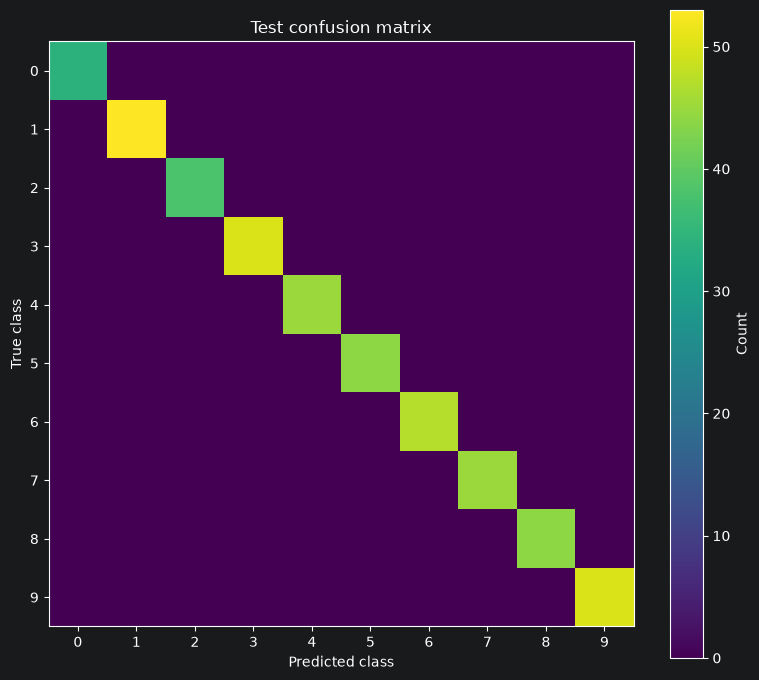

     Class 0: precision=1.000, recall=1.000
     Class 1: precision=1.000, recall=1.000
     Class 2: precision=1.000, recall=1.000
     Class 3: precision=1.000, recall=1.000
     Class 4: precision=1.000, recall=1.000
     Class 5: precision=1.000, recall=1.000
     Class 6: precision=1.000, recall=1.000
     Class 7: precision=1.000, recall=1.000
     Class 8: precision=1.000, recall=1.000
     Class 9: precision=1.000, recall=1.000


In [12]:
def collect_predictions(model, loader, device=device):
    # Collect logits and labels without retaining computation graphs.
    model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            all_logits.append(model(images.to(device)).cpu())
            all_labels.append(labels.cpu())
    return torch.cat(all_logits), torch.cat(all_labels)


test_logits, test_labels = collect_predictions(model, test_loader, device)
test_predictions = test_logits.argmax(dim=1)
test_accuracy = (test_predictions == test_labels).float().mean().item()
print(f"Test accuracy: {test_accuracy:.4f}")


def confusion_matrix_counts(y_true, y_pred, num_classes):
    # Rows are true classes; columns are predicted classes.
    matrix = torch.zeros(num_classes, num_classes, dtype=torch.int64)
    for true_label, predicted_label in zip(y_true, y_pred):
        matrix[int(true_label), int(predicted_label)] += 1
    return matrix


num_classes = 10
cm = confusion_matrix_counts(test_labels, test_predictions, num_classes)
plt.figure(figsize=(8, 7))
plt.imshow(cm.numpy(), interpolation="nearest")
plt.title("Test confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(range(num_classes))
plt.yticks(range(num_classes))
plt.colorbar(label="Count")
plt.tight_layout()
plt.show()

# Compute per-class precision and recall from the confusion matrix.
cm_float = cm.float()
tp = cm_float.diag()
precision = tp / cm_float.sum(dim=0).clamp_min(1)
recall = tp / cm_float.sum(dim=1).clamp_min(1)
for cls in range(num_classes):
    name = class_names[cls] if dataset_source == "Fashion-MNIST" else f"Class {cls}"
    print(f"{name:>12}: precision={precision[cls]:.3f}, recall={recall[cls]:.3f}")

## 13. Inspect predictions and errors

Visual inspection can reveal confusing classes, ambiguous examples, or preprocessing mistakes. It complements numerical metrics but does not replace them.

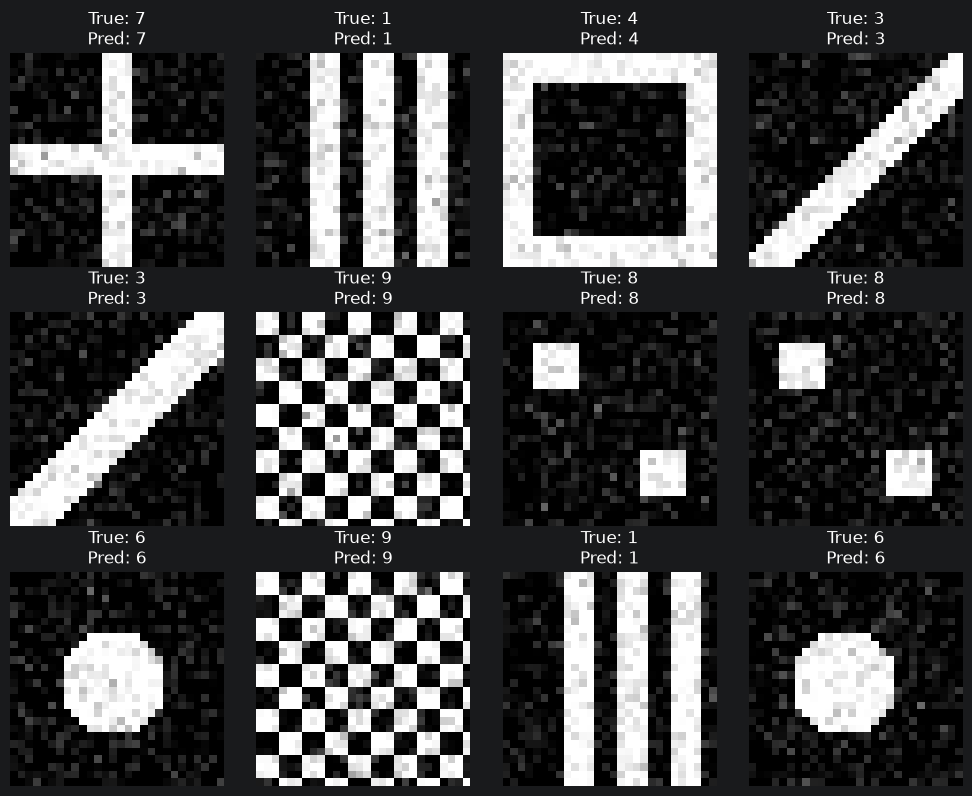

In [13]:
def show_predictions(model, dataset, class_names=None, n_images=12, device=device):
    # Display predictions beside the ground-truth labels.
    indices = np.random.default_rng(SEED).choice(
        len(dataset), size=min(n_images, len(dataset)), replace=False
    )
    fig, axes = plt.subplots(3, 4, figsize=(10, 8))
    model.eval()
    for ax, idx in zip(axes.flat, indices):
        image, label = dataset[int(idx)]
        with torch.no_grad():
            pred = int(model(image.unsqueeze(0).to(device)).argmax(dim=1).item())
        display_image = image.detach().cpu()
        if display_image.min() < 0:
            display_image = display_image * 0.5 + 0.5
        true_name = class_names[int(label)] if class_names is not None else str(int(label))
        pred_name = class_names[pred] if class_names is not None else str(pred)
        ax.imshow(display_image.squeeze(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"True: {true_name}\nPred: {pred_name}")
        ax.axis("off")
    for ax in axes.flat[len(indices):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_predictions(model, test_dataset,
                 class_names if dataset_source == "Fashion-MNIST" else None)

## 14. Visualize learned filters

The first convolutional layer learns filters that respond to local patterns. Visualizing them can be informative, but filter appearance alone does not fully explain the network's predictions.

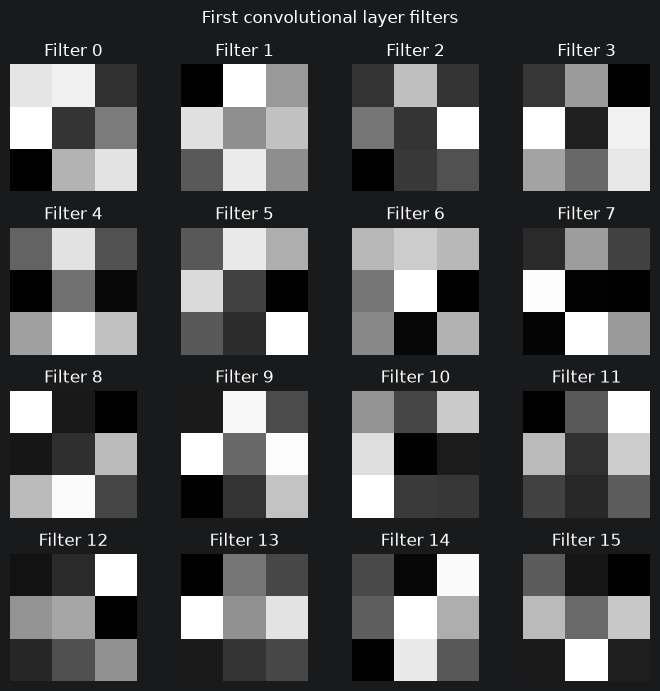

In [14]:
filters = model.features[0].weight.detach().cpu()
fig, axes = plt.subplots(4, 4, figsize=(7, 7))
for i, ax in enumerate(axes.flat):
    if i < filters.shape[0]:
        ax.imshow(filters[i, 0], cmap="gray")
        ax.set_title(f"Filter {i}")
    ax.axis("off")
plt.suptitle("First convolutional layer filters")
plt.tight_layout()
plt.show()

## 15. Visualize intermediate feature maps

A feature map displays the activation pattern of a filter for a particular input. Different filters can respond to different locations and structures. These visualizations help with inspection, but they are not a complete explanation of model behavior.

Feature maps shape: torch.Size([16, 28, 28])


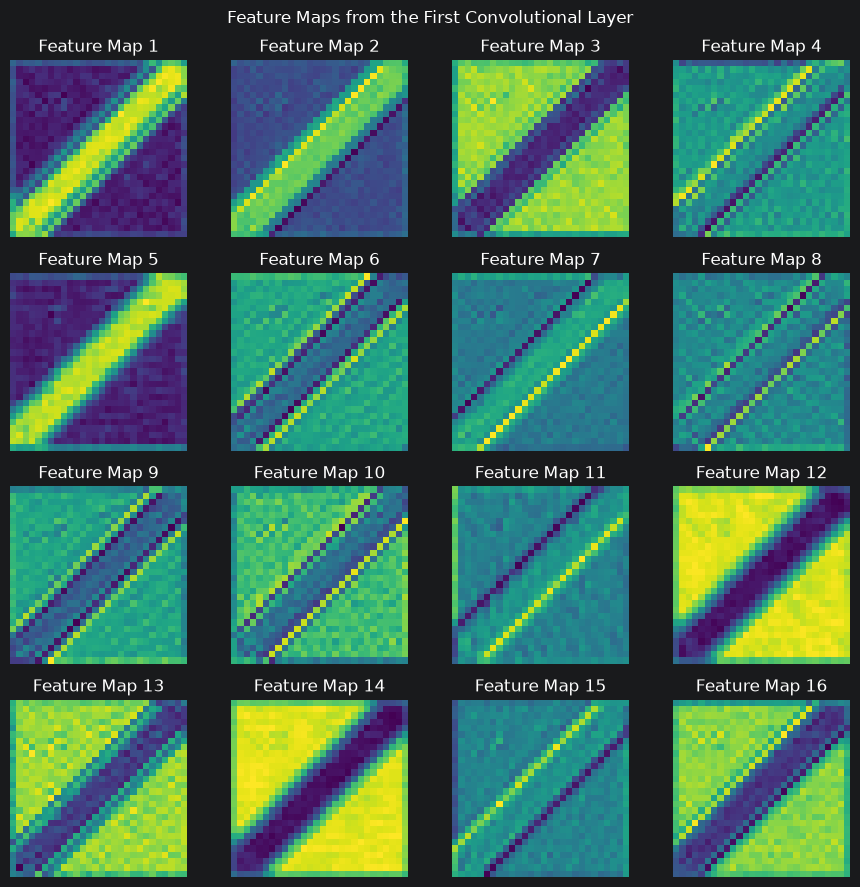

In [15]:
# Capture and visualize feature maps without registering a forward hook.
# This approach is intentionally used in this teaching notebook to avoid
# stale-hook errors when a cell is rerun in Jupyter.

sample_image, sample_label = test_dataset[0]
sample_batch = sample_image.unsqueeze(0).to(device)

model.eval()

# Run the feature extractor layer by layer and save the first convolution output.
x = sample_batch
first_conv_activations = None

with torch.no_grad():
    for layer_index, layer in enumerate(model.features):
        x = layer(x)

        if layer_index == 0:
            # Detach the activations and move them to CPU for visualization.
            first_conv_activations = x.detach().cpu()

# Select feature maps for the single image in the batch.
activations = first_conv_activations[0]

print("Feature maps shape:", activations.shape)

# Display up to 16 feature maps.
num_maps = min(16, activations.shape[0])
fig, axes = plt.subplots(4, 4, figsize=(9, 9))

for i, ax in enumerate(axes.flat):
    if i < num_maps:
        ax.imshow(activations[i].numpy(), cmap="viridis")
        ax.set_title(f"Feature Map {i + 1}")
    ax.axis("off")

plt.suptitle("Feature Maps from the First Convolutional Layer")
plt.tight_layout()
plt.show()


## 16. Normalization and data augmentation

Normalization keeps input scales consistent. Fashion-MNIST in this notebook is transformed from `[0, 1]` to approximately `[-1, 1]`.

Data augmentation applies label-preserving transformations to training images. Crops, flips, or small rotations may help for some tasks, but transformations must respect the domain. For example, a flip may invalidate laterality labels in medical imaging.

Example augmentation pipeline for a task where small rotations are appropriate:

```python
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
```

Apply augmentation to training data only. Validation and test transformations should be deterministic.

## 17. Batch normalization and dropout

- `nn.BatchNorm2d(C)` normalizes channel activations using batch statistics during training and running estimates during evaluation.
- `nn.Dropout(p)` randomly zeros a fraction of activations during training and is disabled by `model.eval()`.

These layers behave differently between training and evaluation, so set the model mode correctly.

## 18. Save and reload a checkpoint

A `state_dict` stores learned parameters. For reproducible experiments or resumed training, also save optimizer state, scheduler state, epoch, and configuration as appropriate. Recreate the same architecture before loading weights, and only load checkpoint files you trust.

In [16]:
checkpoint_path = "cnn_training_checkpoint.pt"
checkpoint = {
    "model_state_dict": model.state_dict(),
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
    "test_accuracy": test_accuracy,
    "config": {
        "num_classes": 10, "dropout": 0.25,
        "batch_size": BATCH_SIZE, "seed": SEED, "dataset": dataset_source
    }
}
torch.save(checkpoint, checkpoint_path)
print("Saved checkpoint:", checkpoint_path)

# Reload the checkpoint created above.
loaded = torch.load(checkpoint_path, map_location=device, weights_only=False)
restored_model = SmallCNN(
    num_classes=loaded["config"]["num_classes"],
    dropout=loaded["config"]["dropout"]
).to(device)
restored_model.load_state_dict(loaded["model_state_dict"])
restored_model.eval()
restored_logits, restored_labels = collect_predictions(restored_model, test_loader, device)
restored_accuracy = (restored_logits.argmax(dim=1) == restored_labels).float().mean().item()
print("Restored model accuracy:", round(restored_accuracy, 4))

Saved checkpoint: cnn_training_checkpoint.pt
Restored model accuracy: 1.0


## 19. Common CNN mistakes

| Problem | Likely cause | What to inspect |
|---|---|---|
| Expected 4D input | Missing batch or channel dimension | Input should be `(N, C, H, W)` |
| Channel mismatch | `in_channels` does not match image channels | Inspect `images.shape[1]` |
| Linear-layer shape error | Incorrect flatten size | Print feature shape before `Linear` |
| Incorrect target format | Wrong loss/label representation | `CrossEntropyLoss` expects integer class IDs shaped `(N,)` |
| Poor learning | Incorrect normalization, labels, or preprocessing | Visualize examples and labels |
| Train score high, validation low | Overfitting or distribution shift | Check regularization and splits |
| Unrealistically high test score | Leakage or duplicate images | Split by independent unit, e.g. patient |
| GPU memory error | Batch/model too large | Reduce batch size or resolution |

For multiclass classification, `CrossEntropyLoss` expects logits shaped `(N, K)` and integer labels shaped `(N,)`. Do not apply softmax before passing logits to this loss.

## 20. Exercises

### Conceptual questions
1. Why are convolutional filters shared across image locations?
2. What do `in_channels` and `out_channels` represent?
3. How do stride and padding affect spatial dimensions?
4. Why do CNNs use nonlinear activations?
5. Compare max pooling and average pooling.
6. Why does `CrossEntropyLoss` expect logits rather than softmax probabilities?
7. Explain the difference between `model.eval()` and `torch.no_grad()`.
8. Why can accuracy hide class-specific errors?
9. Why might a flip be invalid for a medical-imaging task?
10. What leakage can occur if images from one patient appear in train and test sets?

### Coding exercises
1. Change the first convolution from 16 to 32 output channels and recalculate parameter count.
2. Replace a pooling layer with a stride-2 convolution.
3. Use global average pooling instead of a large flattened dense layer.
4. Compare dropout values `0.0`, `0.25`, and `0.5`.
5. Add a learning-rate scheduler and compare curves.
6. Display only misclassified examples.
7. Compute macro-averaged precision and recall.
8. Compare batch sizes 64, 128, and 256.
9. Add a domain-appropriate augmentation pipeline.
10. Repeat training with three seeds and report mean and standard deviation.

### Challenge project
Train a CNN on an image dataset relevant to your interests. Document dataset provenance and licensing, split design, preprocessing, architecture, optimizer, learning rate, regularization, learning curves, confusion matrix, error analysis, limitations, and potential leakage.

## 21. Quick reference

### Convolution
```python
nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1)
```

### Common block
```python
nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.MaxPool2d(2)
)
```

### Multiclass classification
```python
logits = model(images)                        # (N, num_classes)
loss = nn.CrossEntropyLoss()(logits, labels)  # labels: integer class IDs
predictions = logits.argmax(dim=1)
```

### Training and evaluation modes
```python
model.train()
model.eval()
with torch.no_grad():
    logits = model(images)
```

### Essential shapes
- Input images: `(N, C, H, W)`
- Convolution output: `(N, C_out, H_out, W_out)`
- Classifier logits: `(N, num_classes)`
- `CrossEntropyLoss` targets: `(N,)`, integer class indices

## 22. Key takeaways and next notebook

- CNNs learn spatial filters using local connectivity and parameter sharing.
- Kernel size, stride, padding, channels, and pooling determine feature-map shapes.
- Use logits with `CrossEntropyLoss` for multiclass classification.
- Correct train/evaluation modes matter for batch normalization and dropout.
- Confusion matrices, per-class metrics, and error analysis reveal more than accuracy alone.
- Reliable evaluation requires appropriate splits, preprocessing, and leakage prevention.
- Filter and feature-map visualizations are useful diagnostics, not complete explanations.

**Suggested next notebook:** `07 — Transfer Learning and Fine-Tuning`, using pretrained CNNs, replacing classification heads, freezing/unfreezing layers, and adapting models to new image datasets.